# MLP-01: TF-IDF Vectorization & Classifier Training Pipeline

**Project:** Fake News Detection System  
**Milestone:** Milestone 2 (The Core Model)  
**Inputs:** `data/processed_news.csv` (`DAT-01`) + `backend/preprocessing.py` (`NLP-01`)  
**Outputs:** `models/model.pkl` (consumed by `MLP-02` & `MLP-03`)


## 1. Environment & Imports

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import sys
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Ensure project root is importable from notebooks/
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from backend.preprocessing import preprocess_text, warmup

sns.set_theme(style='whitegrid', palette='muted')
DATA_PATH = PROJECT_ROOT / 'data' / 'processed_news.csv'
MODEL_PATH = PROJECT_ROOT / 'models' / 'model.pkl'
RANDOM_STATE = 42

print(f'scikit-learn: {sklearn.__version__}')
print(f'Dataset path: {DATA_PATH} (exists={DATA_PATH.exists()})')

scikit-learn: 1.9.1
Dataset path: C:\DEV\FakeNewsDetection\data\processed_news.csv (exists=True)


## 2. Load Cleaned Corpus & Apply `NLP-01` Preprocessing

We concatenate `title` + `text` (matching live inference in `API-01`) and apply `backend.preprocessing.preprocess_text()` so training and serving use identical linguistic normalization.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Loaded {len(df):,} records | columns={list(df.columns)}')

raw_corpus = df['title'].fillna('').astype(str) + '\n\n' + df['text'].fillna('').astype(str)

warmup()
t0 = time.perf_counter()
df['clean_text'] = raw_corpus.apply(preprocess_text)
elapsed = time.perf_counter() - t0
print(f'Preprocessed {len(df):,} articles in {elapsed:.2f}s ({elapsed / len(df) * 1000:.2f} ms/article)')

# Drop any rows that became empty after noise/stopword removal
before_drop = len(df)
df = df[df['clean_text'].str.strip() != ''].copy().reset_index(drop=True)
print(f'Dropped {before_drop - len(df)} empty post-preprocessing rows; remaining: {len(df):,}')
print('Class distribution:', df['label'].value_counts().to_dict())

Loaded 38,656 records | columns=['id', 'title', 'text', 'label']
Preprocessed 38,656 articles in 18.22s (0.47 ms/article)
Dropped 5 empty post-preprocessing rows; remaining: 38,651
Class distribution: {1: 21195, 0: 17456}


## 3. Stratified Train / Validation / Test Split (`80% / 10% / 10%`)

In [3]:
X = df['clean_text']
y = df['label'].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print(f'Train: {len(X_train):,} ({len(X_train)/len(df):.1%}) | REAL ratio={y_train.mean():.4f}')
print(f'Val:   {len(X_val):,} ({len(X_val)/len(df):.1%}) | REAL ratio={y_val.mean():.4f}')
print(f'Test:  {len(X_test):,} ({len(X_test)/len(df):.1%}) | REAL ratio={y_test.mean():.4f}')

Train: 30,920 (80.0%) | REAL ratio=0.5484
Val:   3,865 (10.0%) | REAL ratio=0.5483
Test:  3,866 (10.0%) | REAL ratio=0.5484


## 4. TF-IDF Vectorization & Classifier Comparison (Validation Set)

Compare `LogisticRegression` (native calibrated `predict_proba` + direct `coef_`) against `CalibratedClassifierCV(PassiveAggressiveClassifier)`.

In [4]:
def make_tfidf() -> TfidfVectorizer:
    return TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=50_000,
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
    )

def evaluate_pipeline(model: Pipeline, X_split, y_split) -> dict[str, float]:
    preds = model.predict(X_split)
    probs = model.predict_proba(X_split)[:, 1]
    return {
        'accuracy': float(accuracy_score(y_split, preds)),
        'precision': float(precision_score(y_split, preds)),
        'recall': float(recall_score(y_split, preds)),
        'f1': float(f1_score(y_split, preds)),
        'roc_auc': float(roc_auc_score(y_split, probs)),
    }

candidates = {
    'LogisticRegression': Pipeline([
        ('tfidf', make_tfidf()),
        ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    'CalibratedPassiveAggressive': Pipeline([
        ('tfidf', make_tfidf()),
        ('classifier', CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
            cv=5,
            method='sigmoid',
        )),
    ]),
}

val_results = []
for name, pipe in candidates.items():
    t_start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)
        pipe.fit(X_train, y_train)
    fit_sec = time.perf_counter() - t_start
    metrics = evaluate_pipeline(pipe, X_val, y_val)
    metrics['model'] = name
    metrics['fit_seconds'] = round(fit_sec, 2)
    val_results.append(metrics)

val_df = pd.DataFrame(val_results).set_index('model')
display(val_df.round(4))

# Select winner; prefer LogisticRegression on near-ties (<= 0.002 F1) for native coef_ & calibration
lr_f1 = val_df.loc['LogisticRegression', 'f1']
pa_f1 = val_df.loc['CalibratedPassiveAggressive', 'f1']
best_model_name = 'CalibratedPassiveAggressive' if (pa_f1 - lr_f1) > 0.002 else 'LogisticRegression'
best_pipeline = candidates[best_model_name]
print(f'Selected best pipeline: {best_model_name} (val F1={val_df.loc[best_model_name, "f1"]:.4f})')

c:\DEV\FakeNewsDetection\.venv\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)


,accuracy,precision,recall,f1,roc_auc,fit_seconds
model,,,,,,
LogisticRegression,0.9824,0.9772,0.9910,0.9841,0.9984,17.75
CalibratedPassiveAggressive,0.9907,0.9892,0.9939,0.9915,0.9994,16.28


Selected best pipeline: CalibratedPassiveAggressive (val F1=0.9915)


## 5. Held-Out Test Evaluation & Leakage Audit

=== Held-Out Test Set Metrics ===
    accuracy: 0.9928
   precision: 0.9915
      recall: 0.9953
          f1: 0.9934
     roc_auc: 0.9993

Classification Report:
              precision    recall  f1-score   support

    FAKE (0)       0.99      0.99      0.99      1746
    REAL (1)       0.99      1.00      0.99      2120

    accuracy                           0.99      3866
   macro avg       0.99      0.99      0.99      3866
weighted avg       0.99      0.99      0.99      3866



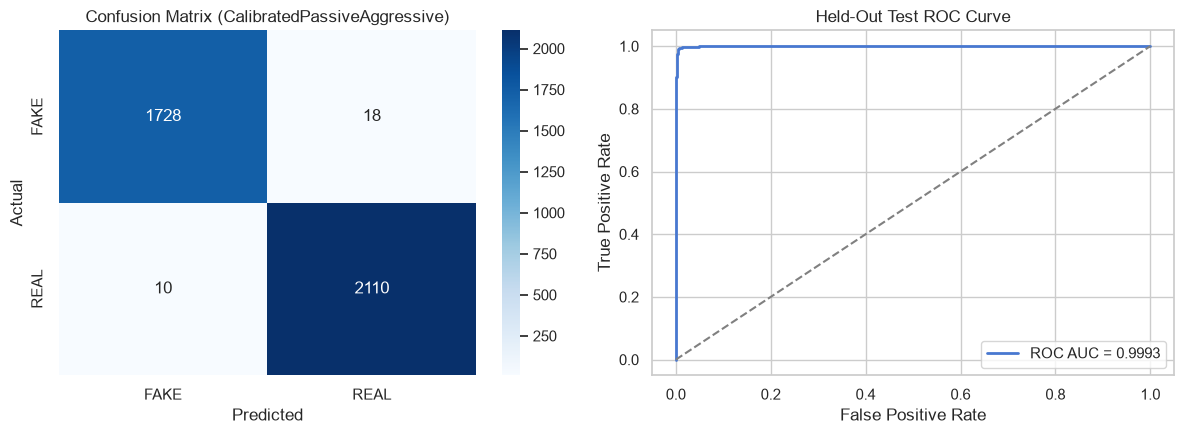

In [5]:
test_metrics = evaluate_pipeline(best_pipeline, X_test, y_test)
test_preds = best_pipeline.predict(X_test)
test_probs = best_pipeline.predict_proba(X_test)[:, 1]

print('=== Held-Out Test Set Metrics ===')
for k, v in test_metrics.items():
    print(f'  {k:>10}: {v:.4f}')

print('\nClassification Report:')
print(classification_report(y_test, test_preds, target_names=['FAKE (0)', 'REAL (1)']))

assert test_metrics['f1'] >= 0.90, f'Test F1 below 0.90 threshold: {test_metrics["f1"]:.4f}'

# Plot Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['FAKE', 'REAL'], yticklabels=['FAKE', 'REAL'], ax=axes[0])
axes[0].set_title(f'Confusion Matrix ({best_model_name})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, test_probs)
axes[1].plot(fpr, tpr, label=f'ROC AUC = {test_metrics["roc_auc"]:.4f}', lw=2)
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_title('Held-Out Test ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

In [6]:
# Inspect top feature weights to verify no 'reuters' publisher leakage
vectorizer = best_pipeline.named_steps['tfidf']
classifier = best_pipeline.named_steps['classifier']
feature_names = vectorizer.get_feature_names_out()

if hasattr(classifier, 'coef_'):
    weights = classifier.coef_[0]
else:
    weights = np.mean([c.estimator.coef_[0] for c in classifier.calibrated_classifiers_], axis=0)

top_real_idx = np.argsort(weights)[-15:][::-1]
top_fake_idx = np.argsort(weights)[:15]

print('Top 15 REAL-leaning features:', [(feature_names[i], round(float(weights[i]), 3)) for i in top_real_idx])
print('Top 15 FAKE-leaning features:', [(feature_names[i], round(float(weights[i]), 3)) for i in top_fake_idx])
assert 'reuters' not in set(feature_names[top_real_idx]), 'Publisher leakage detected in top features!'

Top 15 REAL-leaning features: [('say', 7.891), ('president donald', 4.92), ('tuesday', 3.828), ('wednesday', 3.783), ('thursday', 3.314), ('nov', 3.02), ('president barack', 2.917), ('friday', 2.569), ('representative', 2.495), ('monday', 2.494), ('say statement', 2.394), ('rival', 2.383), ('republican', 2.269), ('democratic', 2.118), ('news conference', 2.109)]
Top 15 FAKE-leaning features: [('via', -11.235), ('video', -7.981), ('read', -7.236), ('president trump', -5.166), ('image', -5.071), ('gop', -4.98), ('feature image', -4.327), ('obama', -4.298), ('sen', -3.728), ('feature', -3.705), ('mr', -3.666), ('hillary', -3.622), ('getty', -3.534), ('image via', -3.478), ('getty image', -3.364)]


## 6. Serialize & Verify `models/model.pkl`

In [7]:
artifact = {
    'pipeline': best_pipeline,
    'vectorizer': vectorizer,
    'classifier': classifier,
    'classes': {0: 'FAKE', 1: 'REAL'},
    'metadata': {
        'model_name': best_model_name,
        'sklearn_version': sklearn.__version__,
        'trained_at': datetime.now(timezone.utc).isoformat(),
        'vocab_size': len(feature_names),
        'train_size': len(X_train),
        'val_size': len(X_val),
        'test_size': len(X_test),
        'metrics': test_metrics,
    },
}

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(artifact, MODEL_PATH, compress=3)
print(f'Saved model artifact to {MODEL_PATH} ({MODEL_PATH.stat().st_size / (1024*1024):.2f} MB)')

# Reload and run smoke verification
reloaded = joblib.load(MODEL_PATH)
sample = preprocess_text('Central bank officials held interest rates steady following quarterly inflation figures.')
probs = reloaded['pipeline'].predict_proba([sample])[0]
print(f'Reloaded smoke test -> FAKE={probs[0]:.4f}, REAL={probs[1]:.4f}')

Saved model artifact to C:\DEV\FakeNewsDetection\models\model.pkl (2.38 MB)
Reloaded smoke test -> FAKE=0.0066, REAL=0.9934


c:\DEV\FakeNewsDetection\.venv\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)
